# How did each COVID-19 wave travel across New York State?

Did each wave start in New York City and spread outward, and did that pattern change from the first wave in 2020 to Omicron?

**Data** (downloaded and checked by `fetch_data.py`):
- Daily COVID-19 tests and positive results for all 62 counties, March 2020 to August 2023: [New York State Department of Health](https://health.data.ny.gov/Health/New-York-State-Statewide-COVID-19-Testing/xdss-u53e)
- Yearly county population estimates, 2020 to 2023: [US Census Bureau](https://www.census.gov/data/tables/time-series/demo/popest/2020s-counties-total.html)
- County boundaries: [Cornell University Geospatial Information Repository](https://cugir.library.cornell.edu/catalog/cugir-007865)

**Approach**
1. Turn daily positive tests into a 7-day average rate per 100,000 residents, using each year's population estimate
2. Find the statewide waves from the peaks in the statewide curve
3. For each county and wave, find the wave's *midpoint*: the date by which half of that county's cases in the wave had been reported
4. Compare each county's midpoint with New York City's, against its distance from the city

In [1]:
import json
import logging

import geopandas as gpd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, LogNorm, TwoSlopeNorm
from scipy.signal import find_peaks
from scipy.stats import spearmanr, theilslopes

# chart style: white background; amber = before NYC, purple = after NYC, with a neutral gray midpoint
INK, INK2, MUTED, GRID, SHADE = '#1f1d2b', '#4a4856', '#6b6a75', '#e4e2ea', '#f1f0ee'
PURPLE, LAVENDER = '#6e4eba', '#ddd5f4'
PURPLES = LinearSegmentedColormap.from_list('purples', ['#fbfaff', '#e3dcf7', '#b9a8e8', '#8b6fd3', '#6e4eba', '#4d3fb4', '#2b2170'])
DIVERGING = LinearSegmentedColormap.from_list('amber_purple', ['#8f5c00', '#c98500', '#ecd3a0', '#f1f0ee', '#cdc3ee', '#6e4eba', '#4d3fb4'])
# Inter if it's installed, otherwise matplotlib's default font (without a warning)
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
plt.rcParams.update({'font.family': ['Inter', 'DejaVu Sans'], 'font.size': 10, 'axes.edgecolor': '#c9c7d1',
                     'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.titlecolor': INK,
                     'axes.spines.top': False, 'axes.spines.right': False, 'figure.facecolor': 'white'})


def header(fig, title, subtitle):
    # chart title and subtitle at a fixed distance from the top, whatever the figure height
    h = fig.get_figheight()
    fig.text(0.045, 1 - 0.3 / h, title, fontsize=19, fontweight='semibold', color=INK, va='top')
    fig.text(0.045, 1 - 0.72 / h, subtitle, fontsize=10.5, color=MUTED, va='top')


NYC = ['Bronx', 'Kings', 'New York', 'Queens', 'Richmond']  # the five boroughs
MIN_POPULATION = 20_000  # counties smaller than this are mapped but left out of the statistics (too noisy)

## 1. Load the data and join population to testing

In [2]:
testing = pd.read_csv('data/ny_covid_testing_by_county.csv', parse_dates=['test_date'])
population = pd.read_csv('data/ny_county_population.csv')
counties = gpd.read_file('data/cugir-007865-geojson.json').dissolve(by='name').reset_index()  # some counties come in several pieces

# join each day to that year's population estimate; validate='m:1' stops the join if a county-year is duplicated
testing['year'] = testing['test_date'].dt.year
df = testing.merge(population, on=['county', 'year'], how='left', validate='m:1')
assert df['population'].notna().all(), 'some county-days have no population estimate'

# 7-day average of new positive tests per 100,000 residents (centred, so it doesn't lag the real timing)
df = df.sort_values(['county', 'test_date']).reset_index(drop=True)
df['rate'] = (df['new_positives'] / df['population'] * 1e5)
df['rate_7d'] = df.groupby('county')['rate'].transform(lambda x: x.rolling(7, center=True).mean())

print(f"{len(df):,} county-days, {df['county'].nunique()} counties, {df['test_date'].min():%b %Y} to {df['test_date'].max():%b %Y}")

79,236 county-days, 62 counties, Mar 2020 to Aug 2023


## 2. Cumulative incidence by county

The share of each county's residents with a reported positive test from March 2020 to August 2023, per 100,000. Hover over a county to see its value. This counts positive tests, not infections: it misses people who never tested, and it can count reinfections more than once.

In [3]:
import folium

latest = population[population['year'] == 2023].set_index('county')['population']
cumulative = (df.groupby('county')['new_positives'].sum() / latest * 1e5).rename('cumulative_incidence').round(0)

shapes = counties[['name', 'geometry']].merge(cumulative, left_on='name', right_index=True, how='left', validate='1:1')
assert shapes['cumulative_incidence'].notna().all()

m = folium.Map(location=[42.9, -75.5], zoom_start=6, tiles='cartodbpositron')
folium.Choropleth(geo_data=shapes.to_json(), data=shapes, columns=['name', 'cumulative_incidence'],
                  key_on='feature.properties.name', fill_color='Blues', fill_opacity=0.8, line_opacity=0.3,
                  legend_name='Positive tests per 100,000 residents, Mar 2020 - Aug 2023').add_to(m)
folium.GeoJson(shapes.to_json(), style_function=lambda f: {'fillOpacity': 0, 'weight': 0},
               tooltip=folium.GeoJsonTooltip(['name', 'cumulative_incidence'],
                                             aliases=['County', 'Positive tests per 100,000'],
                                             localize=True)).add_to(m)
m.save('maps/cumulative_incidence.html')
m

## 3. Find the statewide waves

Peaks in the statewide 7-day rate mark the waves, and the low points between them mark where one wave ends and the next begins. I kept the four waves whose peaks rose at least 40 cases per 100,000 above the surrounding low points. The two smaller waves later in 2022 are left out: by then most people were testing at home, so reported tests tracked the virus less closely.

Delta (late 2021) never formed a separate statewide low point before Omicron arrived. Omicron was first detected in New York in early December 2021, so I start the Omicron wave on 1 December 2021.

In [4]:
state = df.groupby('test_date')[['new_positives', 'population']].sum()
state['rate_7d'] = (state['new_positives'] / state['population'] * 1e5).rolling(7, center=True).mean()

curve = state['rate_7d'].fillna(0).to_numpy()
peaks, props = find_peaks(curve, prominence=10, distance=45)
troughs = [0] + [p + np.argmin(curve[p:q]) for p, q in zip(peaks[:-1], peaks[1:])] + [len(curve) - 1]

names = ['Spring 2020', 'Winter 2020-21', 'Omicron', 'Spring 2022']
big_peaks = [i for i, prom in enumerate(props['prominences']) if prom >= 40]
assert len(big_peaks) == len(names), f'expected 4 large waves, found {len(big_peaks)}'

waves = {}
for name, i in zip(names, big_peaks):
    start, end = state.index[troughs[i]], state.index[troughs[i + 1]]
    if name == 'Omicron':
        start = pd.Timestamp('2021-12-01')  # separate Omicron from Delta
    waves[name] = (start, end)

pd.DataFrame(waves, index=['start', 'end']).T.map(lambda d: d.date())

,start,end
Spring 2020,2020-03-01,2020-08-22
Winter 2020-21,2020-08-22,2021-06-22
Omicron,2021-12-01,2022-03-08
Spring 2022,2022-03-08,2022-06-18


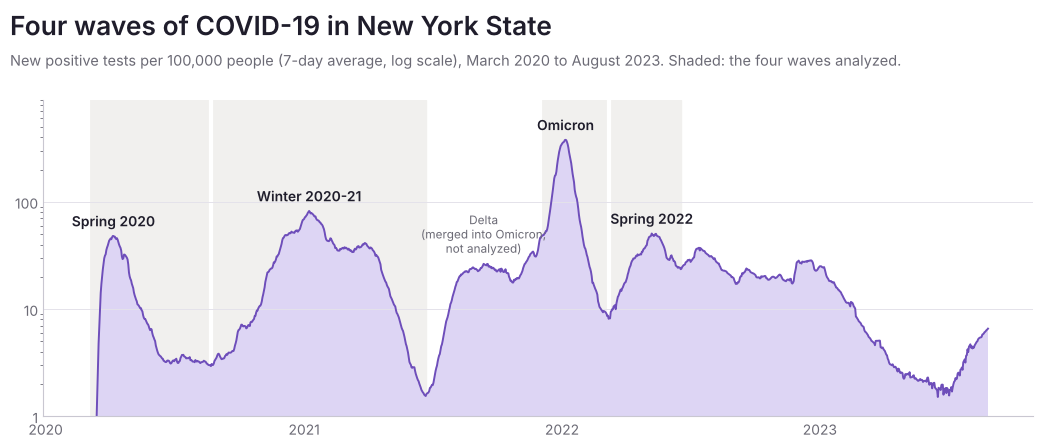

In [5]:
fig = plt.figure(figsize=(11, 4.8))
header(fig, 'Four waves of COVID-19 in New York State',
       'New positive tests per 100,000 people (7-day average, log scale), March 2020 to August 2023. '
       'Shaded: the four waves analyzed.')
ax = fig.add_axes([0.075, 0.09, 0.9, 0.66])
ax.fill_between(state.index, state['rate_7d'], color=LAVENDER, lw=0)
ax.plot(state.index, state['rate_7d'], color=PURPLE, lw=1.4)
for name, (start, end) in waves.items():
    ax.axvspan(start, end, color=SHADE, zorder=0)
    ax.axvline(start, color='white', lw=3, zorder=0)
    peak_day = state.loc[start:end, 'rate_7d'].idxmax()
    ax.annotate(name, (peak_day, state.loc[peak_day, 'rate_7d']), xytext=(0, 7), textcoords='offset points',
                ha='center', fontsize=10, fontweight='semibold', color=INK)
delta_peak = state.loc['2021-07-01':'2021-10-31', 'rate_7d'].idxmax()
ax.annotate('Delta\n(merged into Omicron;\nnot analyzed)', (delta_peak, state.loc[delta_peak, 'rate_7d']), xytext=(0, 8),
            textcoords='offset points', ha='center', fontsize=8.5, color=MUTED)
ax.set_yscale('log')
ax.set_ylim(1, 900)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.grid(axis='y', color=GRID, lw=0.7)
ax.tick_params(length=0)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.savefig('img/statewide_waves.png', dpi=150)
plt.show()

## 4. Distance from New York City

Each county's distance is measured from its centre to the centre of the five boroughs combined.

In [6]:
projected = counties.to_crs(32618)  # UTM zone 18N, a metre-based projection that covers New York
centres = projected.set_index('name').geometry.centroid
nyc_centre = projected[projected['name'].isin(NYC)].dissolve().geometry.centroid.iloc[0]
distance_km = (centres.distance(nyc_centre) / 1000).rename('km')
distance_km.sort_values(ascending=False).head(3).round(0)

name
Niagara       487.0
Chautauqua    485.0
Erie          461.0
Name: km, dtype: float64

## 5. When did each county's wave happen, compared with NYC?

For each wave, a county's **midpoint** is the date by which half of its cases in that wave had been reported. Midpoints are more reliable than peak dates: in a small county, a single noisy week can set the peak. A negative number means the county reached its midpoint *before* NYC.

In [7]:
def midpoint(daily_cases):
    # date by which half of the wave's cases had been reported
    share = daily_cases.cumsum() / daily_cases.sum()
    return share[share >= 0.5].index[0]

nyc_daily = df[df['county'].isin(NYC)].groupby('test_date')['new_positives'].sum()
pop_2021 = population[population['year'] == 2021].set_index('county')['population']

rows = []
for name, (start, end) in waves.items():
    wave = df[df['test_date'].between(start, end)]
    nyc_mid = midpoint(nyc_daily.loc[start:end])
    for county, g in wave.groupby('county'):
        rows.append({'wave': name, 'county': county,
                     'days_vs_nyc': (midpoint(g.set_index('test_date')['new_positives']) - nyc_mid).days})

timing = pd.DataFrame(rows).join(distance_km, on='county').join(pop_2021, on='county')
timing['in_stats'] = ~timing['county'].isin(NYC) & (timing['population'] >= MIN_POPULATION)
timing.head()

,wave,county,days_vs_nyc,km,population,in_stats
0,Spring 2020,Albany,23,211.623229,316178,True
1,Spring 2020,Allegany,28,384.044408,46938,True
2,Spring 2020,Bronx,1,17.959553,1424084,False
3,Spring 2020,Broome,53,227.047794,198562,True
4,Spring 2020,Cattaraugus,49,432.927543,76539,True


In [8]:
def summarise(timing, column):
    out = {}
    for name, g in timing[timing['in_stats']].groupby('wave', sort=False):
        rho, p = spearmanr(g['km'], g[column])
        slope, _, lo, hi = theilslopes(g[column], g['km'])
        out[name] = {'counties': len(g),
                     'median days vs NYC': g[column].median(),
                     'Spearman correlation with distance': round(rho, 2),
                     'p-value': f'{p:.1g}',
                     'days per 100 km': round(slope * 100, 1),
                     '95% CI': f'{lo * 100:.1f} to {hi * 100:.1f}'}
    return pd.DataFrame(out).T

summary = summarise(timing, 'days_vs_nyc')
summary

,counties,median days vs NYC,Spearman correlation with distance,p-value,days per 100 km,95% CI
Spring 2020,55,24.0,0.55,2e-05,9.5,5.8 to 13.6
Winter 2020-21,55,-17.0,-0.34,0.01,-1.9,-3.7 to 0.0
Omicron,55,4.0,0.54,2e-05,1.2,0.6 to 1.6
Spring 2022,55,-7.0,-0.37,0.005,-1.7,-2.8 to 0.0


**Cross-check with peak dates.** The same comparison using each county's peak date (the highest 7-day rate) instead of its midpoint points the same way in every wave, though more noisily:

In [9]:
peak_rows = []
for name, (start, end) in waves.items():
    wave = df[df['test_date'].between(start, end)]
    nyc_rate = (nyc_daily.loc[start:end] / pop_2021[NYC].sum() * 1e5).rolling(7, center=True).mean()
    nyc_peak = nyc_rate.idxmax()
    county_peaks = wave.loc[wave.groupby('county')['rate_7d'].idxmax(), ['county', 'test_date']]
    for _, r in county_peaks.iterrows():
        peak_rows.append({'wave': name, 'county': r['county'], 'peak_days_vs_nyc': (r['test_date'] - nyc_peak).days})

peaks_check = timing.merge(pd.DataFrame(peak_rows), on=['wave', 'county'], validate='1:1')
summarise(peaks_check, 'peak_days_vs_nyc')[['median days vs NYC', 'Spearman correlation with distance', 'days per 100 km']]

,median days vs NYC,Spearman correlation with distance,days per 100 km
Spring 2020,16.0,0.24,5.2
Winter 2020-21,-8.0,-0.3,-0.5
Omicron,2.0,0.51,1.1
Spring 2022,-10.0,-0.41,-1.9


## 6. Charts

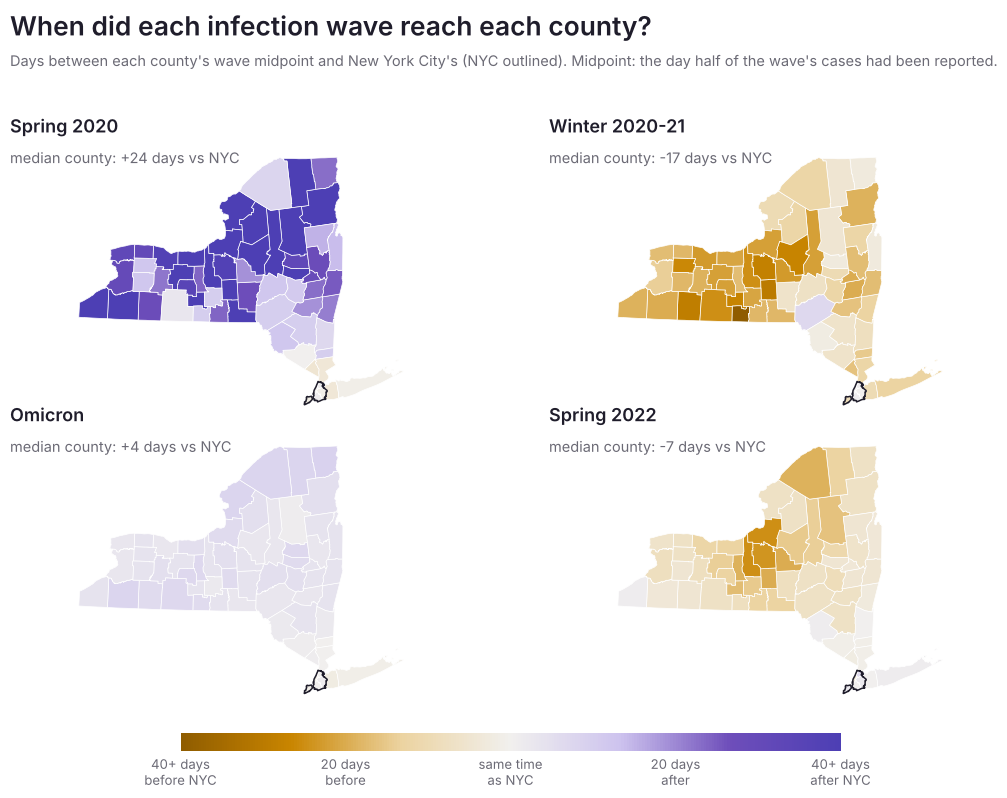

In [10]:
limit = 40
norm = TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit)
fig = plt.figure(figsize=(11, 8.25))
header(fig, 'When did each infection wave reach each county?',
       "Days between each county's wave midpoint and New York City's (NYC outlined). "
       "Midpoint: the day half of the wave's cases had been reported.")
nyc_outline = projected[projected['name'].isin(NYC)].dissolve().boundary
for (x0, y0), (name, g) in zip([(0.03, 0.47), (0.52, 0.47), (0.03, 0.12), (0.52, 0.12)], timing.groupby('wave', sort=False)):
    ax = fig.add_axes([x0, y0, 0.45, 0.33])
    shapes = projected.merge(g, left_on='name', right_on='county', validate='1:1')
    shapes.plot(column=shapes['days_vs_nyc'].clip(-limit, limit), cmap=DIVERGING, norm=norm,
                edgecolor='white', linewidth=0.5, ax=ax)
    nyc_outline.plot(ax=ax, color=INK, linewidth=1.1)
    ax.set_axis_off()
    fig.text(x0 + 0.015, y0 + 0.345, name, fontsize=13, fontweight='semibold', color=INK)
    fig.text(x0 + 0.015, y0 + 0.325, f"median county: {summary.loc[name, 'median days vs NYC']:+.0f} days vs NYC",
             fontsize=10.5, color=MUTED, va='top')
cax = fig.add_axes([0.2, 0.065, 0.6, 0.022])
cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=DIVERGING), cax=cax, orientation='horizontal')
cbar.set_ticks([-40, -20, 0, 20, 40])
cbar.set_ticklabels(['40+ days\nbefore NYC', '20 days\nbefore', 'same time\nas NYC', '20 days\nafter', '40+ days\nafter NYC'])
cbar.ax.tick_params(labelsize=9.5, length=0)
cbar.outline.set_visible(False)
fig.savefig('img/wave_timing_maps.png', dpi=150)
plt.show()

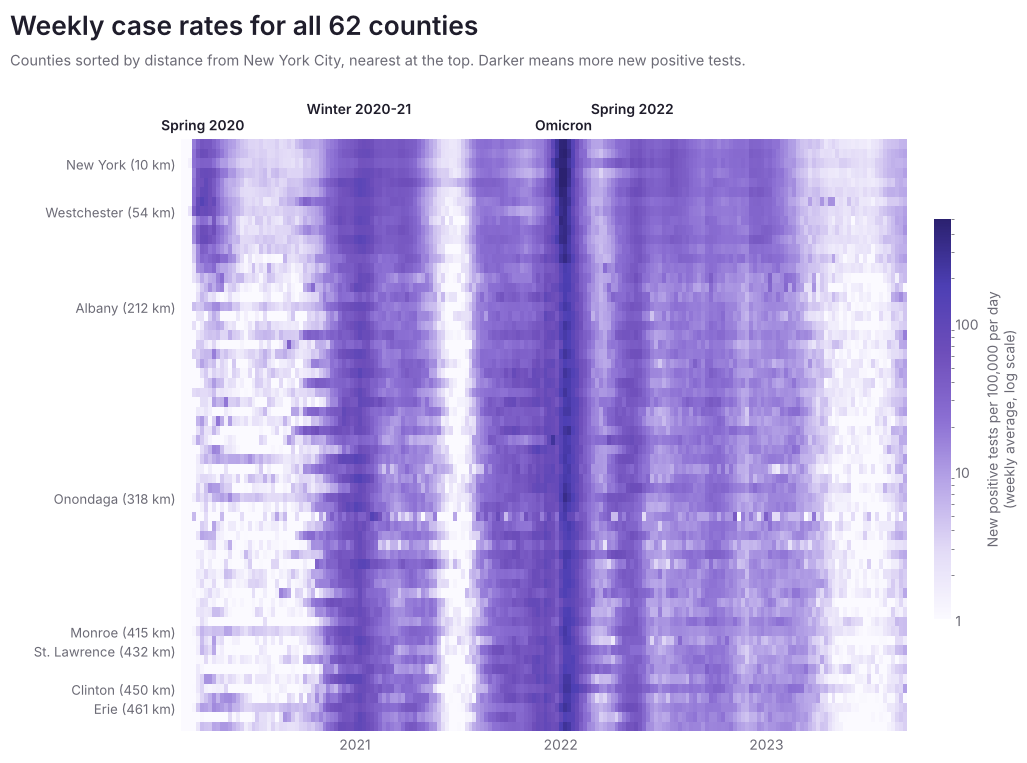

In [11]:
weekly = (df.set_index('test_date').groupby('county')['rate'].resample('W').mean().unstack('test_date'))
order = distance_km.sort_values().index
weekly = weekly.loc[order]

fig = plt.figure(figsize=(11, 8))
header(fig, 'Weekly case rates for all 62 counties',
       'Counties sorted by distance from New York City, nearest at the top. Darker means more new positive tests.')
ax = fig.add_axes([0.2, 0.06, 0.66, 0.74])
mesh = ax.pcolormesh(weekly.columns, np.arange(len(order)) + 0.5, weekly.clip(lower=1).to_numpy(),
                     cmap=PURPLES, norm=LogNorm(vmin=1, vmax=500), shading='nearest')
ticks = [i for i, c in enumerate(order) if c in ['New York', 'Westchester', 'Albany', 'Onondaga', 'Monroe', 'Erie', 'Clinton', 'St. Lawrence']]
ax.set_yticks([t + 0.5 for t in ticks])
ax.set_yticklabels([f"{order[t]} ({distance_km[order[t]]:.0f} km)" for t in ticks], fontsize=9.5)
ax.invert_yaxis()
for k, (name, (start, end)) in enumerate(waves.items()):
    peak_day = state.loc[start:end, 'rate_7d'].idxmax()
    ax.annotate(name, (peak_day, -0.6 - 1.7 * (k % 2)), ha='center', va='bottom', fontsize=10,
                fontweight='semibold', color=INK, annotation_clip=False)
ax.tick_params(length=0)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
for side in ('left', 'bottom'):
    ax.spines[side].set_visible(False)
cax = fig.add_axes([0.885, 0.2, 0.015, 0.5])
cbar = fig.colorbar(mesh, cax=cax)
cbar.set_label('New positive tests per 100,000 per day\n(weekly average, log scale)', color=MUTED)
cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
cbar.ax.tick_params(length=0)
cbar.outline.set_visible(False)
fig.savefig('img/heatmap_by_distance.png', dpi=150)
plt.show()

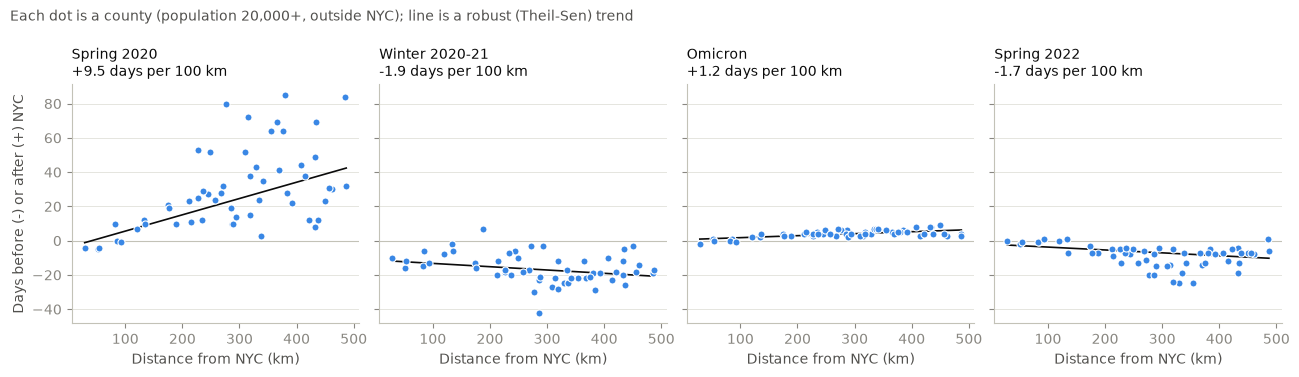

In [12]:
# scatter: days before/after NYC against distance, with a robust trend line, one panel per wave
fig, axes = plt.subplots(1, 4, figsize=(13, 3.8), sharey=True)
for ax, (name, g) in zip(axes, timing[timing['in_stats']].groupby('wave', sort=False)):
    ax.axhline(0, color='#c3c2b7', lw=0.8)
    ax.scatter(g['km'], g['days_vs_nyc'], s=26, color='#3987e5', edgecolor='white', linewidth=0.8, zorder=3)
    slope, intercept, _, _ = theilslopes(g['days_vs_nyc'], g['km'])
    x = np.array([g['km'].min(), g['km'].max()])
    ax.plot(x, intercept + slope * x, color=INK, lw=1.2)
    ax.set_title(f"{name}\n{slope * 100:+.1f} days per 100 km", loc='left', fontsize=10)
    ax.set_xlabel('Distance from NYC (km)')
    ax.grid(axis='y', color=GRID, lw=0.6)
axes[0].set_ylabel('Days before (-) or after (+) NYC')
fig.suptitle(f"Each dot is a county (population {MIN_POPULATION:,}+, outside NYC); line is a robust (Theil-Sen) trend",
             x=0.01, ha='left', fontsize=10, color=INK2)
fig.tight_layout()
fig.savefig('img/delay_vs_distance.png', dpi=150)
plt.show()

## 7. Findings

- **Only the first wave spread outward from NYC.** In spring 2020 the typical county reached its midpoint about three weeks after the city, and the farther away it was, the later it got there. Testing was scarce in March and April 2020, so this wave is the least precisely measured.
- **In winter 2020-21 and spring 2022, upstate went first.** The typical county reached its midpoint one to three weeks *before* NYC. Farther counties tended to be earlier, though this distance trend is weaker than in 2020.
- **Omicron hit the whole state almost at once.** The typical county was only a few days behind the city, with a slight outward gradient of about one day per 100 km.

**Limits.** These are positive tests, not infections, so they depend on who got tested and when. Differences between counties in testing access, especially early in 2020 and after home tests became common, can shift the timing. Distance from NYC is also a stand-in for many things (population density, commuting ties, climate) that this analysis doesn't separate.

## 8. Animated map of weekly case rates

The original version of this project showed an animated map of the pandemic, day by day. This version uses weekly averages to keep the file small, and saves it as a separate page (`maps/weekly_case_rates.html`) that can be opened in a browser.

In [13]:
from folium.plugins import TimeSliderChoropleth
import branca.colormap as cm

weekly_long = weekly.stack().rename('rate').reset_index()
weekly_long['ts'] = (weekly_long['test_date'] - pd.Timestamp('1970-01-01')) // pd.Timedelta('1s')
colours = cm.LinearColormap(['#f4f8fd', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'], vmin=0, vmax=np.log10(500))
weekly_long['color'] = np.log10(weekly_long['rate'].clip(lower=1)).map(colours)

shapes = counties[['name', 'geometry']].reset_index(drop=True)
shapes['id'] = shapes.index.astype(str)
ids = dict(zip(shapes['name'], shapes['id']))
styledict = {ids[c]: {str(r.ts): {'color': r.color, 'opacity': 0.8} for r in g.itertuples()}
             for c, g in weekly_long.groupby('county')}

m = folium.Map(location=[42.9, -75.5], zoom_start=6, tiles='cartodbpositron')
TimeSliderChoropleth(json.loads(shapes.set_index('id').to_json()), styledict=styledict).add_to(m)
m.save('maps/weekly_case_rates.html')
print('saved maps/weekly_case_rates.html')

saved maps/weekly_case_rates.html
